In [10]:
from google.colab import files
import zipfile, os

uploaded = files.upload()
zip_file = next(iter(uploaded))

extract_path = "/content/traffic_dataset"

with zipfile.ZipFile(zip_file, "r") as z:
    z.extractall(extract_path)

print("Dataset extracted!")

Saving Task6_Audit_Reports.zip to Task6_Audit_Reports (1).zip
Dataset extracted!


In [3]:
import os, json, cv2, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter
from glob import glob

In [4]:
json_files = glob(
    extract_path + "/**/_annotations.coco.json",
    recursive=True
)

print("Annotation files found:")
for f in json_files:
    print(f)

Annotation files found:


In [9]:
if not json_files:
    print("Error: No annotation files matching '_annotations.coco.json' were found in the extracted directory.")
    print("Please verify your ZIP file contents or update the search pattern in the previous cell.")
else:
    annotation_file = json_files[0]

    with open(annotation_file, "r") as f:
        coco = json.load(f)

    images = coco["images"]
    annotations = coco["annotations"]
    categories = coco["categories"]

    category_names = {c["id"]: c["name"] for c in categories}

    print("Images:", len(images))
    print("Annotations:", len(annotations))
    print("Categories:", len(categories))
    print("Class names:", list(category_names.values()))

Error: No annotation files matching '_annotations.coco.json' were found in the extracted directory.
Please verify your ZIP file contents or update the search pattern in the previous cell.


In [ ]:
class_counts = Counter(
    ann["category_id"] for ann in annotations
)

class_df = pd.DataFrame([
    {
        "Class": category_names[c["id"]],
        "Count": class_counts.get(c["id"], 0)
    }
    for c in categories
])

class_df["Percentage"] = (
    class_df["Count"] / max(len(annotations), 1) * 100
)

display(class_df)

,Class,Count,Percentage
0,objects,0,0.000000
1,2-Wheeler,4342,23.773544
2,3-Wheeler,1733,9.488611
3,Bus,717,3.925756
4,Hatchback,6313,34.565265
5,LCV,352,1.927289
6,MUV,693,3.794350
7,SUV,762,4.172142
8,Sedan,3030,16.590013
9,T- Traveller -Tempo-traveller-,145,0.793912


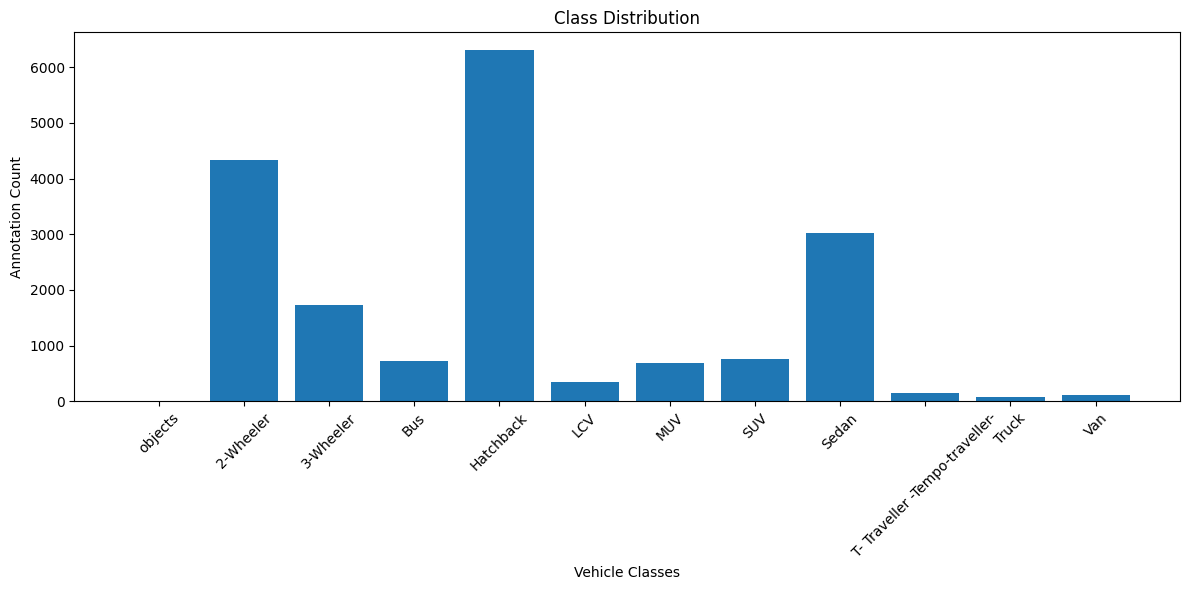

In [ ]:
plt.figure(figsize=(12, 6))

plt.bar(class_df["Class"], class_df["Count"])
plt.title("Class Distribution")
plt.xlabel("Vehicle Classes")
plt.ylabel("Annotation Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
nonzero = class_df[class_df["Count"] > 0]

if len(nonzero) > 0:
    largest = nonzero["Count"].max()
    smallest = nonzero["Count"].min()

    imbalance_ratio = largest / smallest

    print("Largest class:", largest)
    print("Smallest class:", smallest)
    print("Class imbalance ratio:", round(imbalance_ratio, 2))
else:
    print("No annotated classes found.")

print("\nClasses with fewer annotations:")
display(class_df.sort_values("Count").head())

Largest class: 6313
Smallest class: 73
Class imbalance ratio: 86.48

Classes with fewer annotations:


,Class,Count,Percentage
0,objects,0,0.000000
10,Truck,73,0.399693
11,Van,104,0.569426
9,T- Traveller -Tempo-traveller-,145,0.793912
5,LCV,352,1.927289


In [ ]:
image_folder = os.path.dirname(annotation_file)

quality_data = []
corrupted_images = []

for info in images:
    path = os.path.join(image_folder, info["file_name"])

    if not os.path.exists(path):
        matches = glob(
            extract_path + "/**/" + os.path.basename(info["file_name"]),
            recursive=True
        )
        if matches:
            path = matches[0]

    img = cv2.imread(path)

    if img is None:
        corrupted_images.append(info["file_name"])
        continue

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    blur_score = cv2.Laplacian(
        gray, cv2.CV_64F
    ).var()

    brightness = gray.mean()

    height, width = img.shape[:2]

    quality_data.append({
        "Image": info["file_name"],
        "Width": width,
        "Height": height,
        "Blur Score": blur_score,
        "Brightness": brightness
    })

quality_df = pd.DataFrame(quality_data)

blur_threshold = 100

blurry_df = quality_df[
    quality_df["Blur Score"] < blur_threshold
]

total_images = len(images)
readable_images = len(quality_df)
blurry_count = len(blurry_df)
corrupted_count = len(corrupted_images)

blur_rate = blurry_count / max(readable_images, 1) * 100
corruption_rate = corrupted_count / max(total_images, 1) * 100

print("Total Images:", total_images)
print("Readable Images:", readable_images)
print("Potentially Blurry Images:", blurry_count)
print("Corrupted Images:", corrupted_count)

print("Blur Rate: {:.2f}%".format(blur_rate))
print("Corruption Rate: {:.2f}%".format(corruption_rate))

print("\nPotentially blurry image list:")
display(blurry_df.head(20))

Total Images: 531
Readable Images: 531
Potentially Blurry Images: 0
Corrupted Images: 0
Blur Rate: 0.00%
Corruption Rate: 0.00%

Potentially blurry image list:


,Image,Width,Height,Blur Score,Brightness


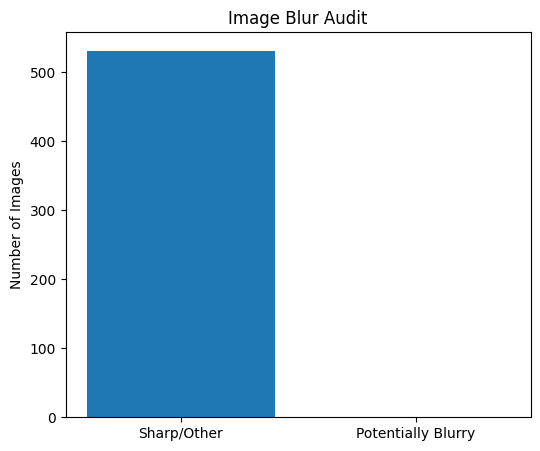

Blur Rate: 0.00%


In [ ]:
plt.figure(figsize=(6, 5))

plt.bar(
    ["Sharp/Other", "Potentially Blurry"],
    [
        readable_images - blurry_count,
        blurry_count
    ]
)

plt.title("Image Blur Audit")
plt.ylabel("Number of Images")
plt.show()

print("Blur Rate: {:.2f}%".format(blur_rate))

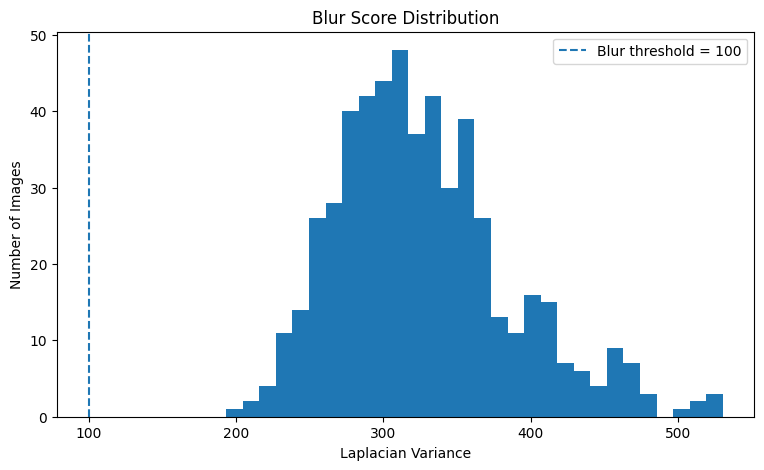

In [ ]:
plt.figure(figsize=(9, 5))

plt.hist(quality_df["Blur Score"], bins=30)

plt.axvline(
    blur_threshold,
    linestyle="--",
    label="Blur threshold = 100"
)

plt.title("Blur Score Distribution")
plt.xlabel("Laplacian Variance")
plt.ylabel("Number of Images")
plt.legend()
plt.show()

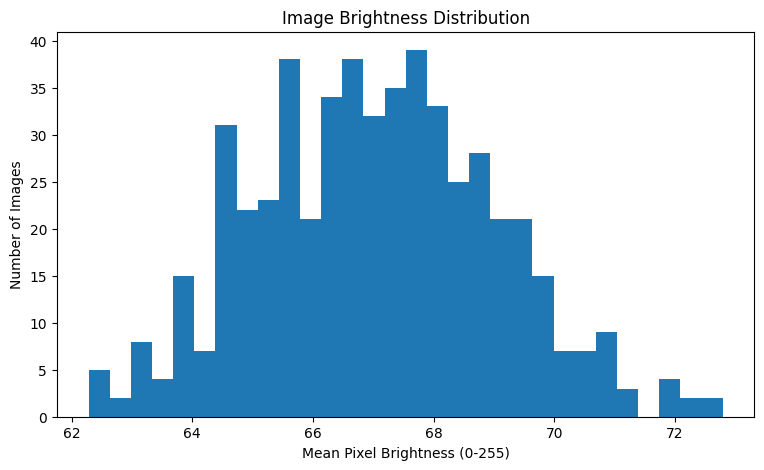

Average brightness: 67.04
Minimum brightness: 62.28
Maximum brightness: 72.79


In [ ]:
plt.figure(figsize=(9, 5))

plt.hist(quality_df["Brightness"], bins=30)

plt.title("Image Brightness Distribution")
plt.xlabel("Mean Pixel Brightness (0-255)")
plt.ylabel("Number of Images")
plt.show()

print("Average brightness:", round(
    quality_df["Brightness"].mean(), 2
))
print("Minimum brightness:", round(
    quality_df["Brightness"].min(), 2
))
print("Maximum brightness:", round(
    quality_df["Brightness"].max(), 2
))

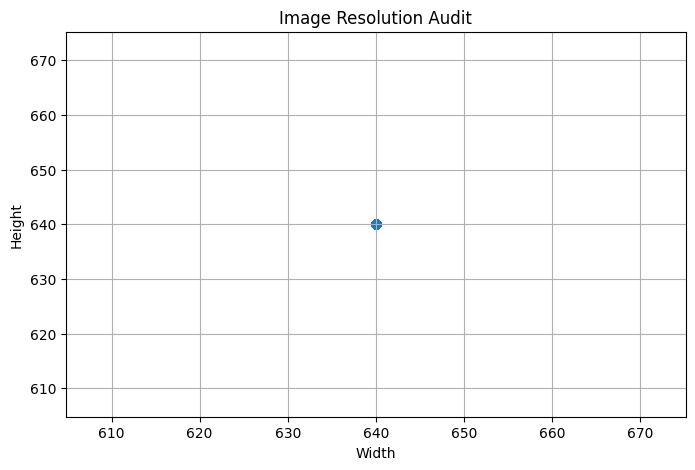

Average width: 640.0
Average height: 640.0


In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    quality_df["Width"],
    quality_df["Height"]
)

plt.title("Image Resolution Audit")
plt.xlabel("Width")
plt.ylabel("Height")
plt.grid()
plt.show()

print("Average width:", round(quality_df["Width"].mean(), 2))
print("Average height:", round(quality_df["Height"].mean(), 2))

In [ ]:
image_lookup = {img["id"]: img for img in images}
category_ids = set(category_names.keys())

invalid_boxes = []
invalid_category = []
invalid_image_ids = []
out_of_bounds = []
invalid_dimensions = []

for ann in annotations:

    if ann["image_id"] not in image_lookup:
        invalid_image_ids.append(ann["id"])
        continue

    if ann["category_id"] not in category_ids:
        invalid_category.append(ann["id"])
        continue

    bbox = ann.get("bbox", [])

    if len(bbox) != 4:
        invalid_boxes.append(ann["id"])
        continue

    x, y, w, h = bbox

    if not all(np.isfinite(v) for v in bbox):
        invalid_boxes.append(ann["id"])
        continue

    if w <= 0 or h <= 0:
        invalid_dimensions.append(ann["id"])
        continue

    img_info = image_lookup[ann["image_id"]]

    if (
        x < 0 or y < 0 or
        x + w > img_info["width"] or
        y + h > img_info["height"]
    ):
        out_of_bounds.append(ann["id"])

print("Invalid bbox format:", len(invalid_boxes))
print("Invalid category IDs:", len(invalid_category))
print("Invalid image IDs:", len(invalid_image_ids))
print("Invalid box dimensions:", len(invalid_dimensions))
print("Boxes outside image:", len(out_of_bounds))

Invalid bbox format: 0
Invalid category IDs: 0
Invalid image IDs: 0
Invalid box dimensions: 0
Boxes outside image: 0


In [ ]:
annotated_image_ids = set(
    ann["image_id"] for ann in annotations
)

unannotated_images = [
    img for img in images
    if img["id"] not in annotated_image_ids
]

print("Images without annotations:", len(unannotated_images))

Images without annotations: 0


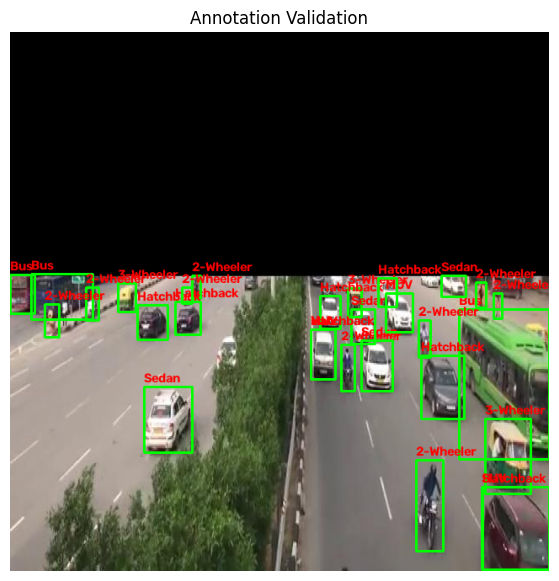

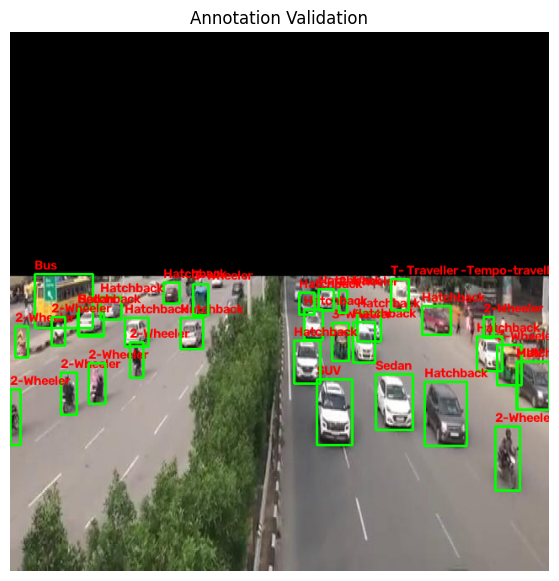

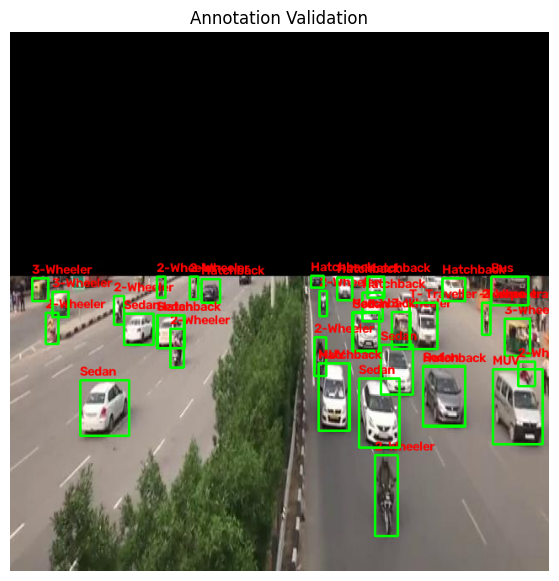

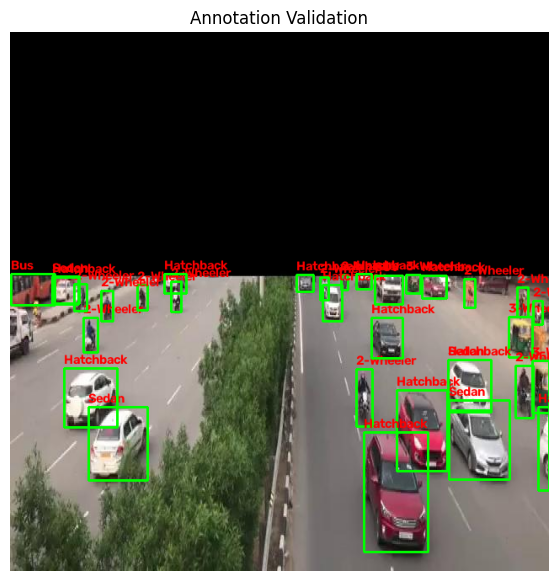

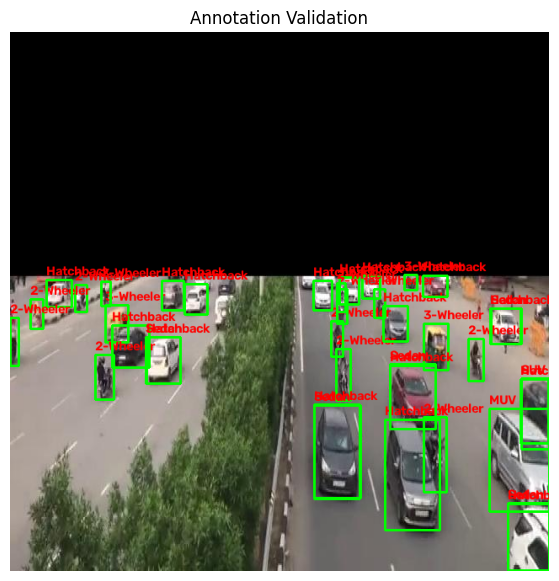

In [ ]:
random.seed(42)

samples = random.sample(
    images, min(5, len(images))
)

for info in samples:

    path = os.path.join(
        image_folder, info["file_name"]
    )

    if not os.path.exists(path):
        matches = glob(
            extract_path + "/**/" + os.path.basename(info["file_name"]),
            recursive=True
        )
        if matches:
            path = matches[0]

    img = cv2.imread(path)

    if img is None:
        continue

    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    for ann in annotations:

        if ann["image_id"] != info["id"]:
            continue

        x, y, w, h = ann["bbox"]

        x1, y1 = int(x), int(y)
        x2, y2 = int(x+w), int(y+h)

        cv2.rectangle(
            img, (x1, y1), (x2, y2),
            (0, 255, 0), 2
        )

        label = category_names[ann["category_id"]]

        cv2.putText(
            img, label, (x1, max(20, y1-5)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5, (255, 0, 0), 2
        )

    plt.figure(figsize=(10, 7))
    plt.imshow(img)
    plt.title("Annotation Validation")
    plt.axis("off")
    plt.show()

In [ ]:
print("=" * 45)
print("       DATASET AUDIT SUMMARY")
print("=" * 45)

print("Total Images:", total_images)
print("Readable Images:", readable_images)
print("Corrupted Images:", corrupted_count)
print("Potentially Blurry Images:", blurry_count)
print("Blur Rate: {:.2f}%".format(blur_rate))
print("Corruption Rate: {:.2f}%".format(corruption_rate))
print("Total Annotations:", len(annotations))
print("Total Classes:", len(categories))
print("Images without Annotations:", len(unannotated_images))
print("Invalid Bboxes:", len(invalid_boxes))
print("Invalid Category IDs:", len(invalid_category))
print("Invalid Image IDs:", len(invalid_image_ids))
print("Invalid Dimensions:", len(invalid_dimensions))
print("Out-of-Bounds Boxes:", len(out_of_bounds))

print("=" * 45)
print("       AUDIT COMPLETED")
print("=" * 45)

       DATASET AUDIT SUMMARY
Total Images: 531
Readable Images: 531
Corrupted Images: 0
Potentially Blurry Images: 0
Blur Rate: 0.00%
Corruption Rate: 0.00%
Total Annotations: 18264
Total Classes: 12
Images without Annotations: 0
Invalid Bboxes: 0
Invalid Category IDs: 0
Invalid Image IDs: 0
Invalid Dimensions: 0
Out-of-Bounds Boxes: 0
       AUDIT COMPLETED


In [ ]:
quality_df.to_csv(
    "/content/image_quality_report.csv",
    index=False
)

class_df.to_csv(
    "/content/class_distribution_report.csv",
    index=False
)

print("Reports saved!")

files.download("/content/image_quality_report.csv")
files.download("/content/class_distribution_report.csv")

Reports saved!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>